# Lab 7: Naive Bayes Classification (Gaussian NB) on the Raisin Dataset
**Name:** Harshit Widhwani &nbsp;|&nbsp; **Section:** B &nbsp;|&nbsp; **Batch:** B4 &nbsp;|&nbsp; **Roll No:** 49  
**Course:** Machine Learning (ML-TP) 24CS03TH0501

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)
#Display setting
pd.set_option('display.max_columns',None)
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_excel("Raisin_Dataset.xlsx")

In [3]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [4]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [5]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [7]:
df.dtypes

Area                 int64
MajorAxisLength    float64
MinorAxisLength    float64
Eccentricity       float64
ConvexArea           int64
Extent             float64
Perimeter          float64
Class               object
dtype: object

In [8]:
df.columns

Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter', 'Class'],
      dtype='object')

In [9]:
df.shape

(900, 8)

In [10]:
df.isnull().sum()

Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["Class"].unique()

array(['Kecimen', 'Besni'], dtype=object)

In [13]:
df["Class"].value_counts()

Class
Kecimen    450
Besni      450
Name: count, dtype: int64

### Bar-Plot

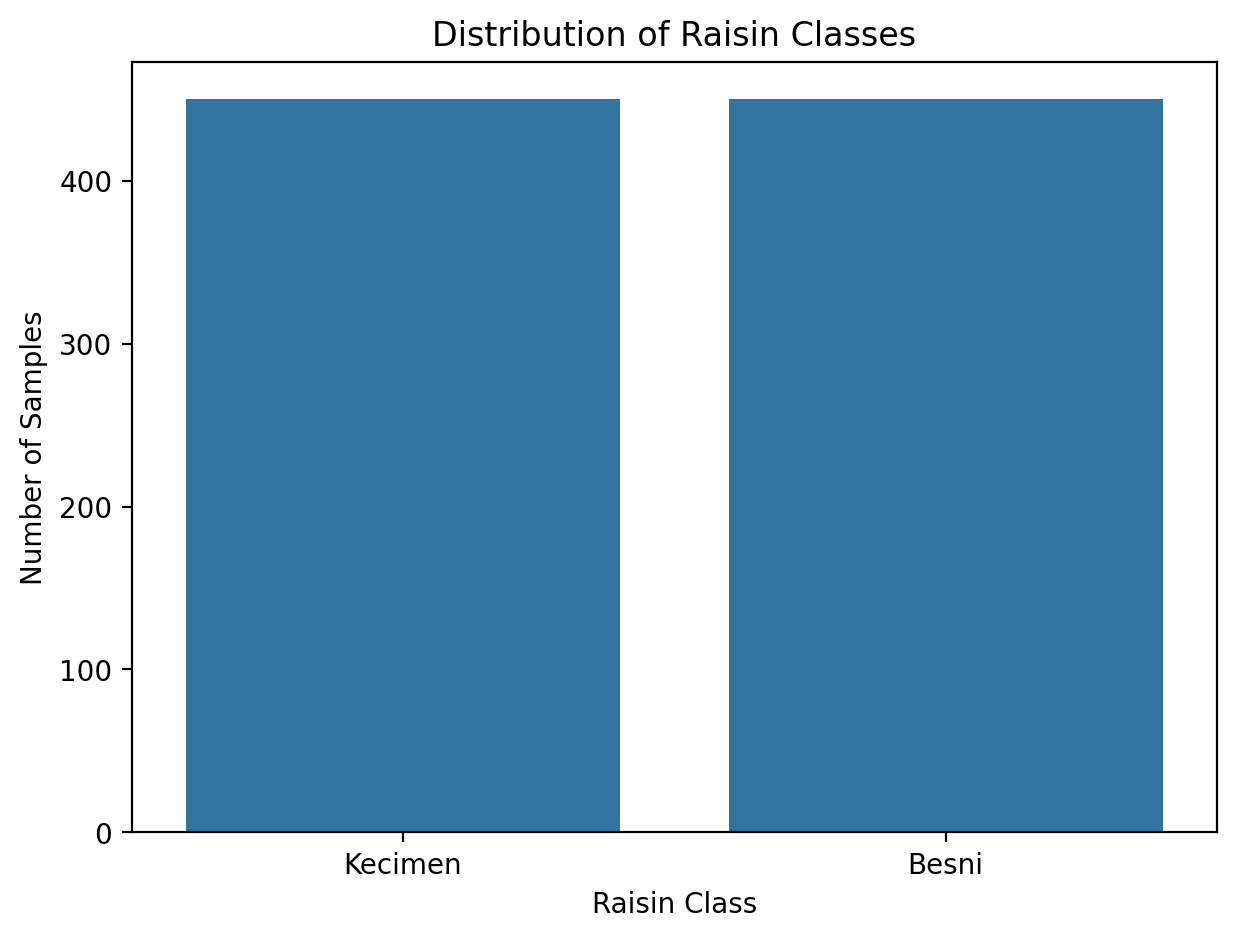

In [14]:
plt.figure(figsize=(7,5))
sns.countplot(x="Class",data=df)

plt.title("Distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of Samples")
plt.show()

### Pie-Chart

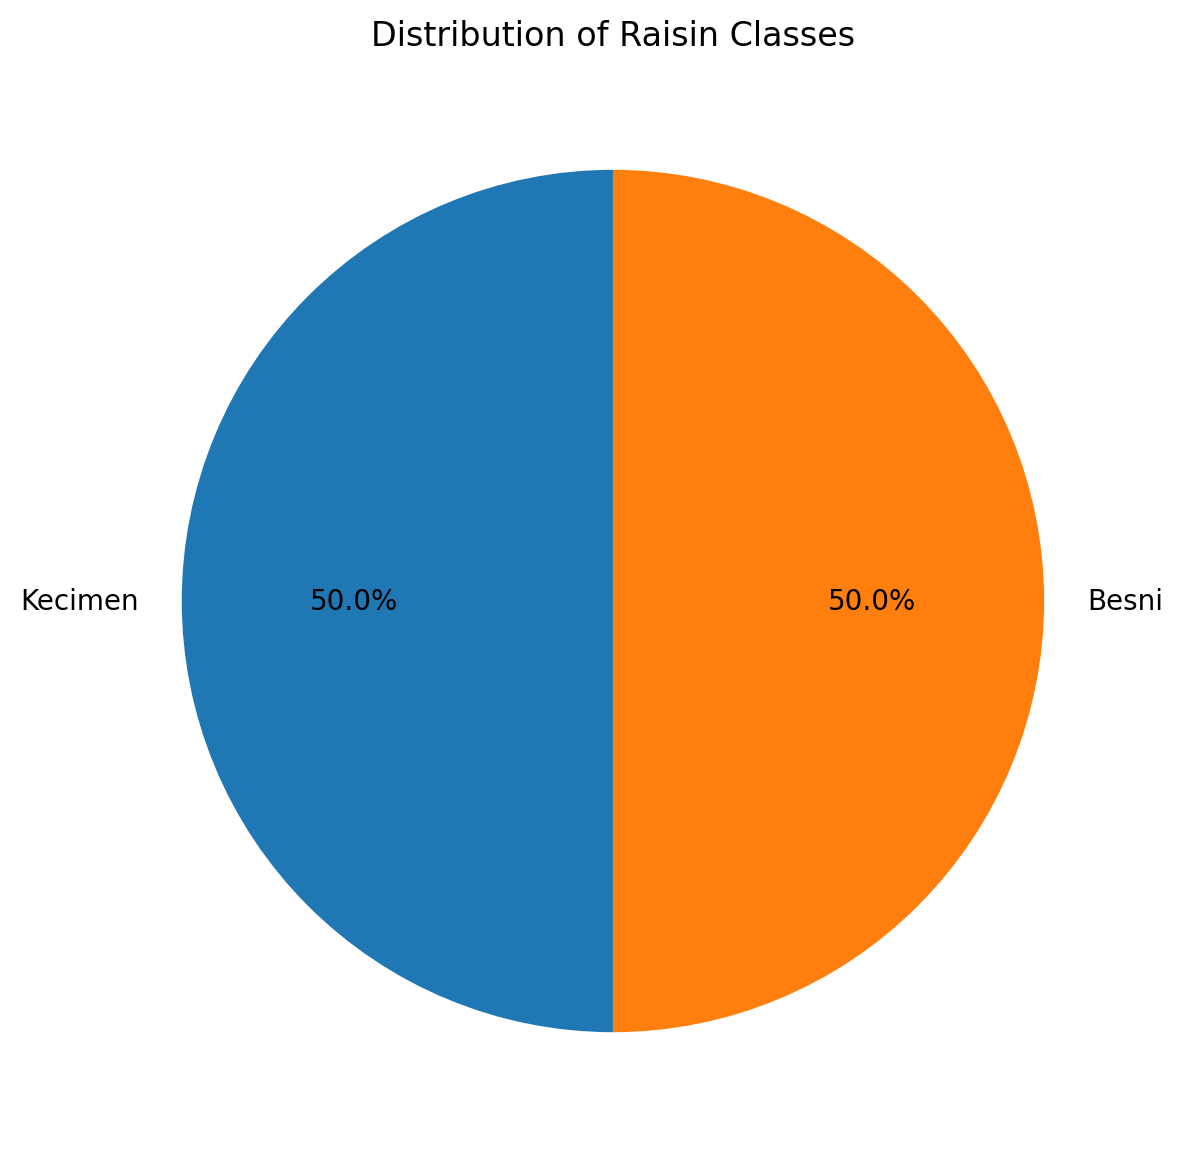

In [15]:
class_counts = df["Class"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Distribution of Raisin Classes")
plt.show()

### Histograms

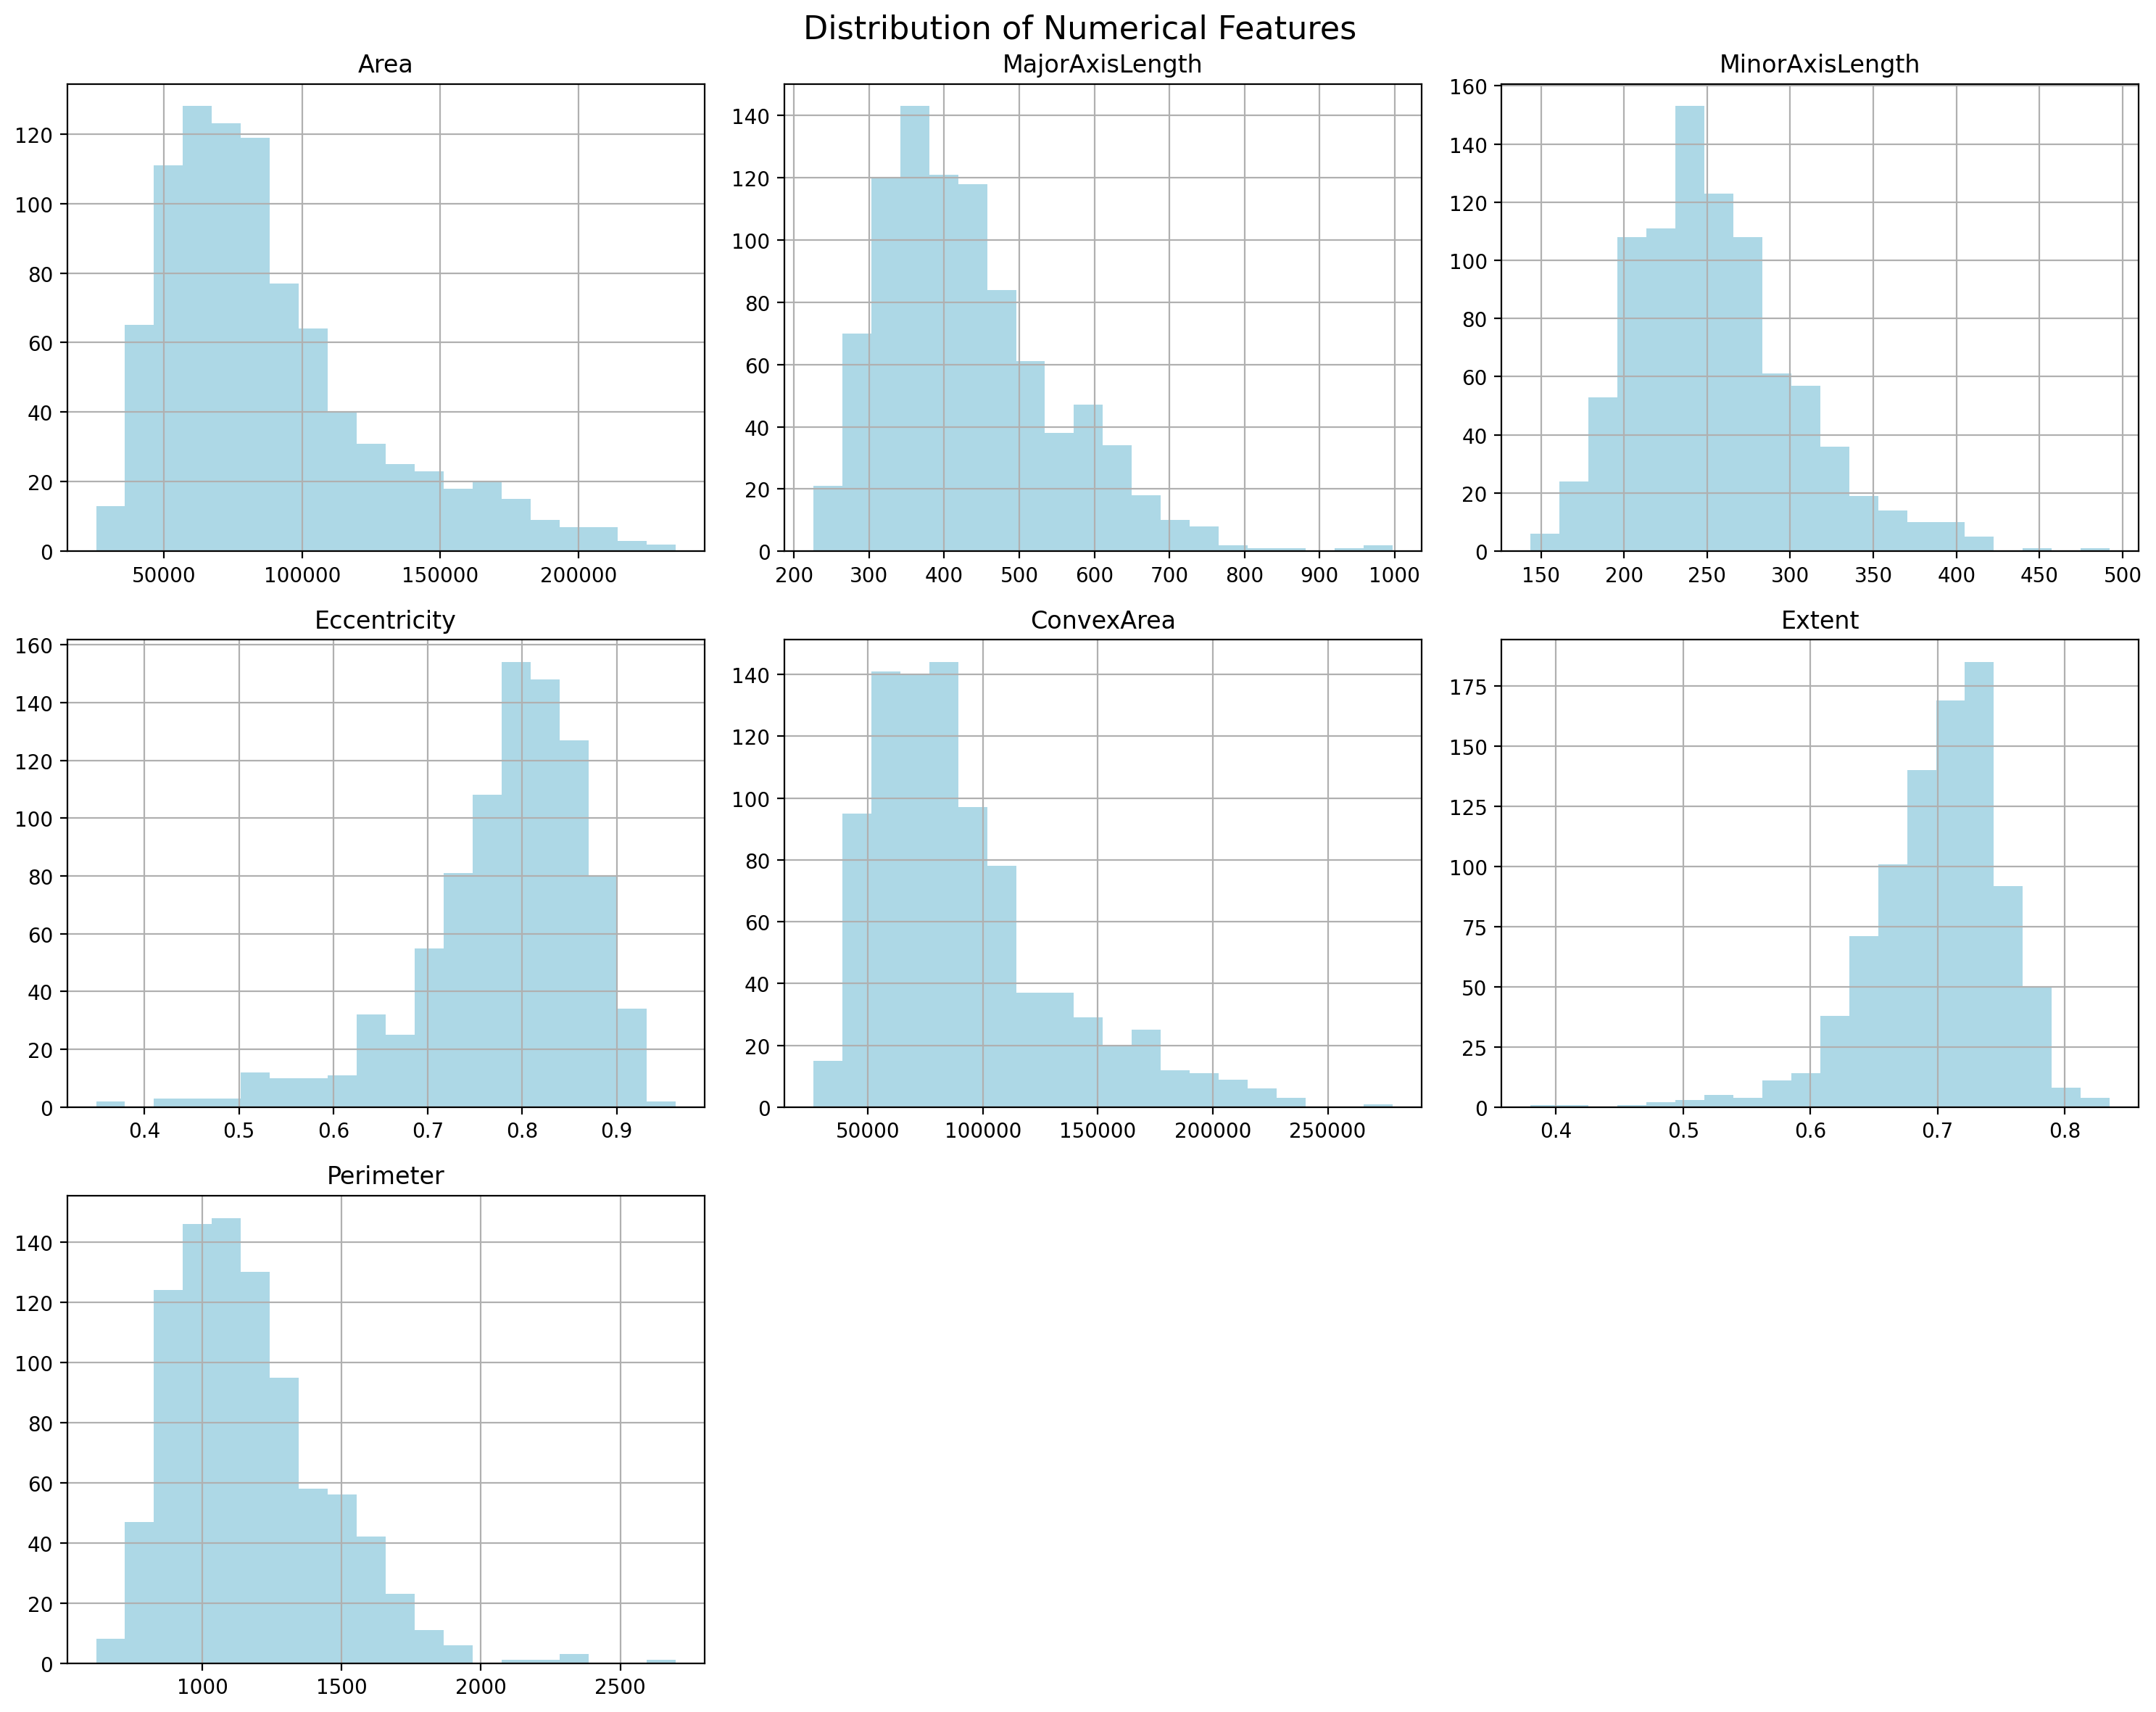

In [16]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns
df[numerical_features].hist(figsize=(15,12),bins=20,color='lightblue')
plt.suptitle("Distribution of Numerical Features",fontsize=16,)

plt.tight_layout()
plt.show()

### Box Plots

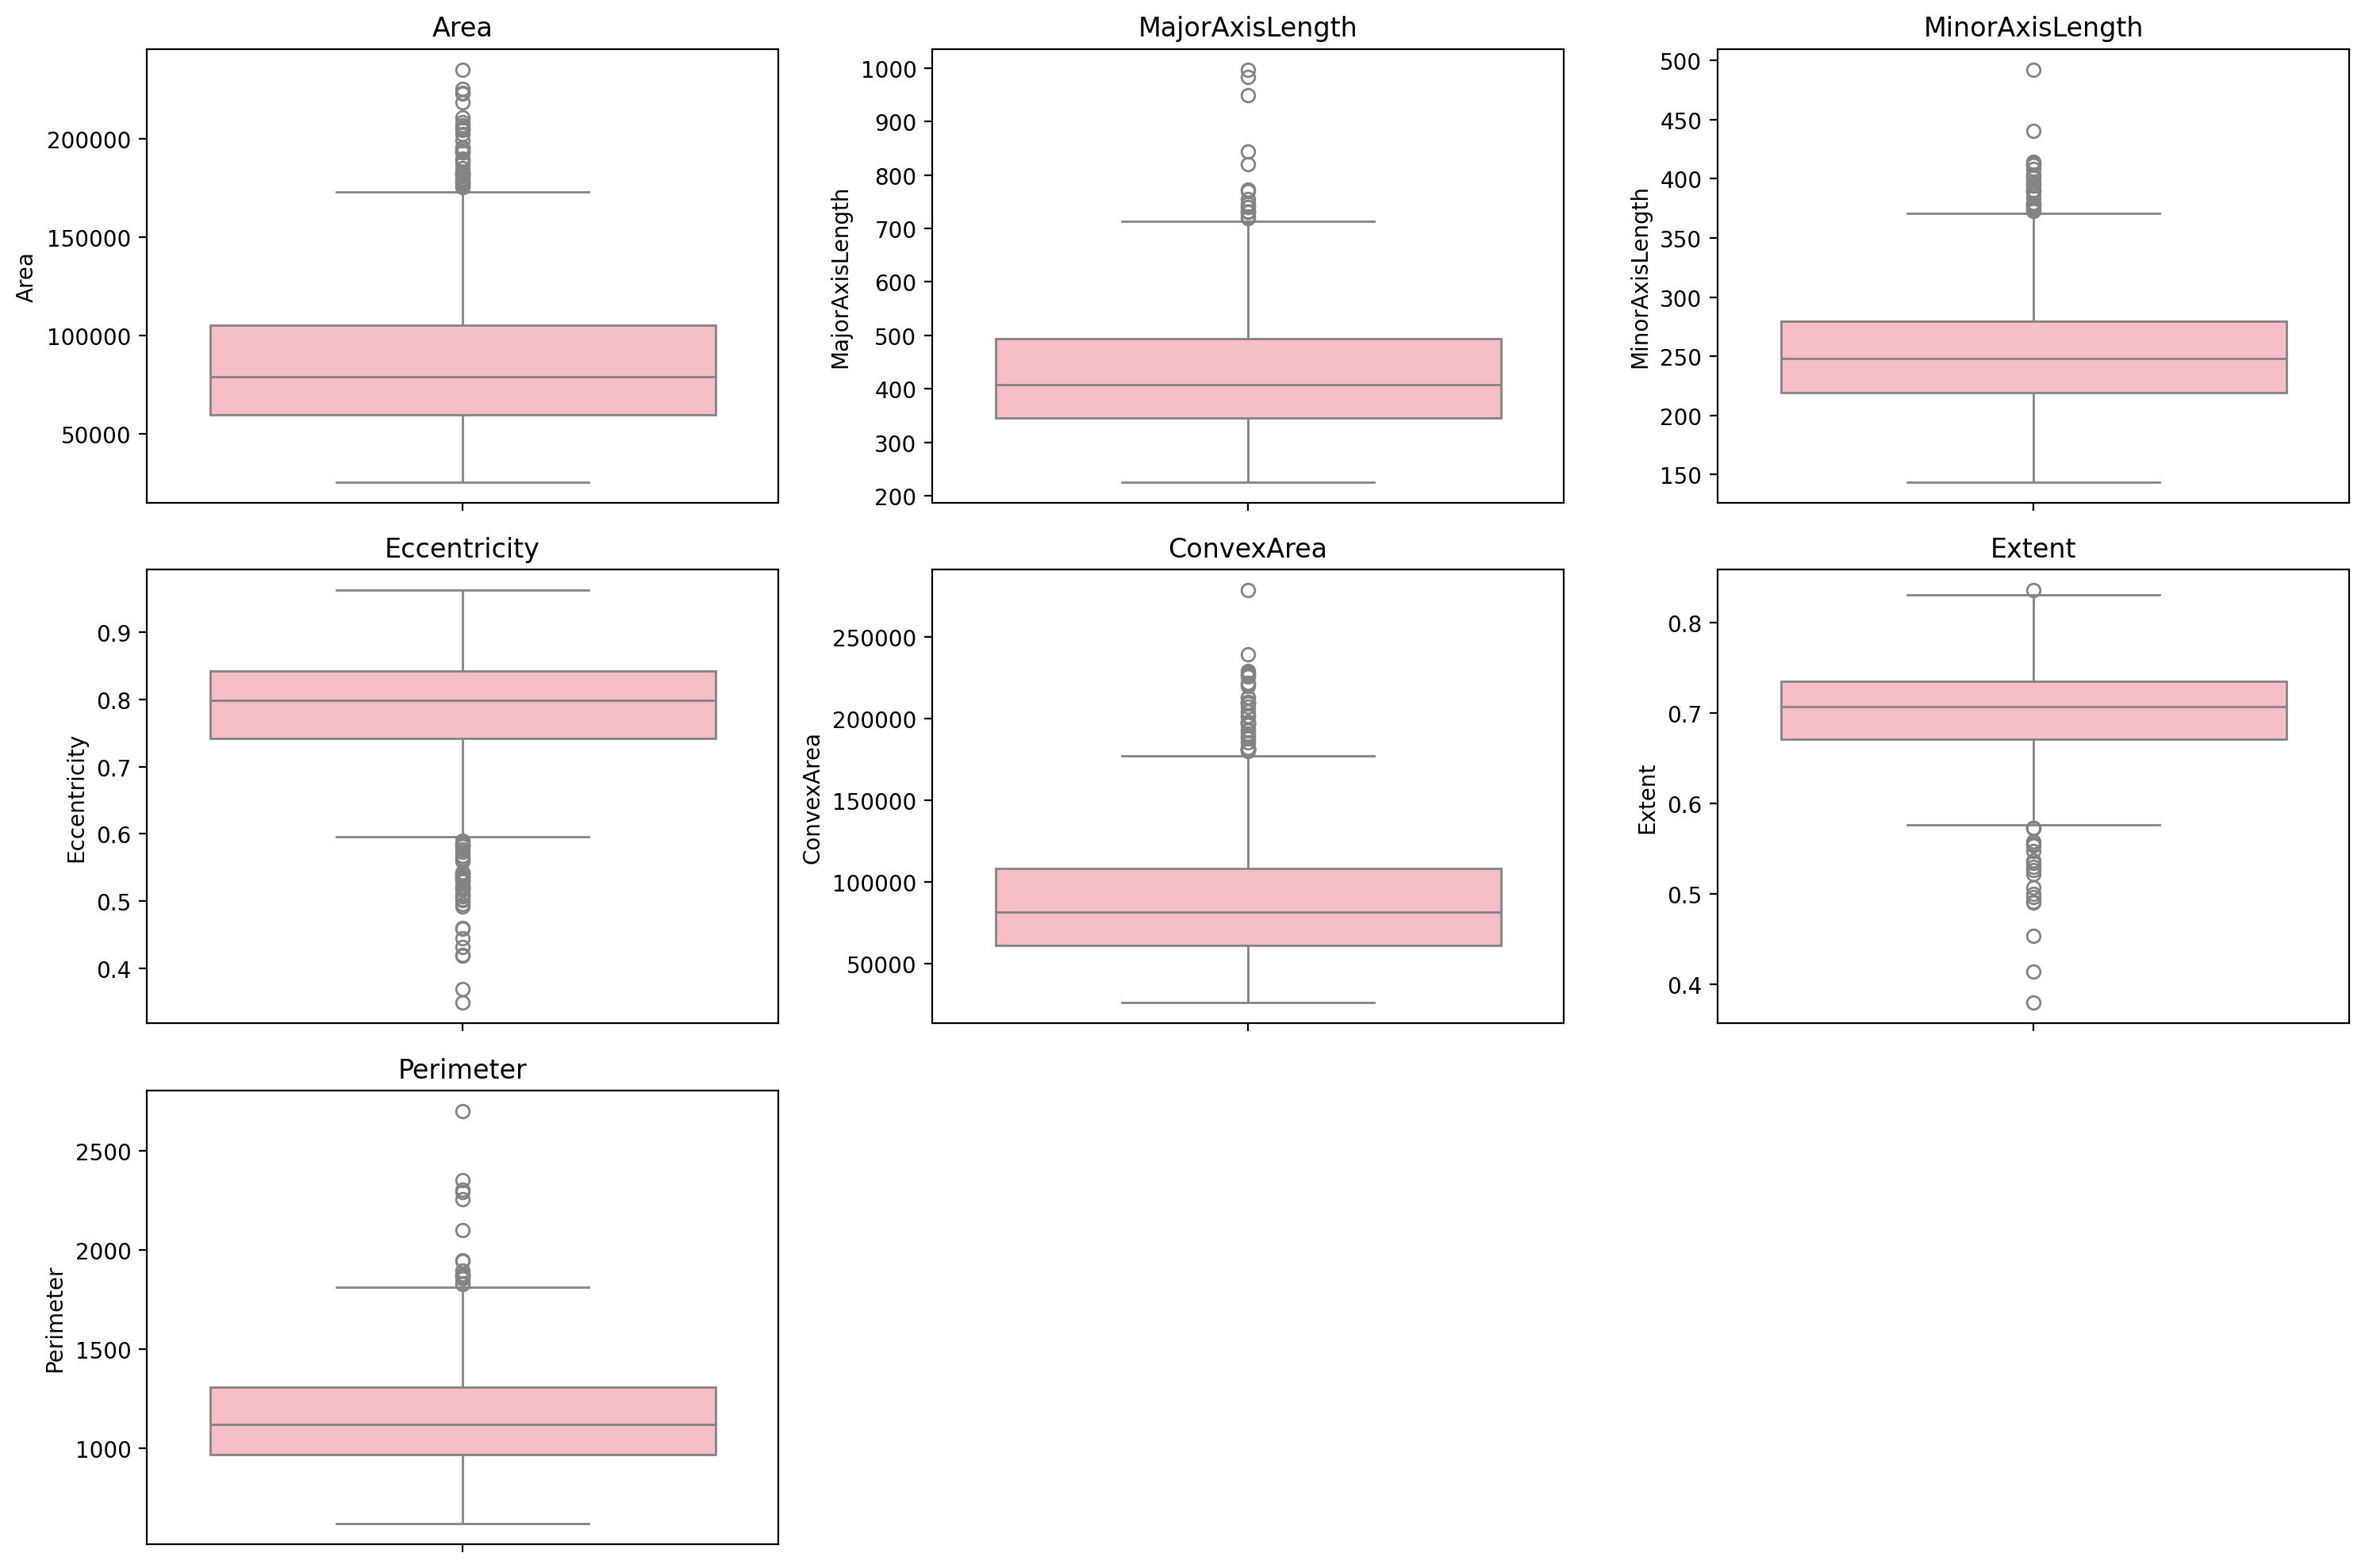

In [17]:
plt.figure(figsize=(15,10))
for i, column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[column],color='lightpink')
    plt.title(column)
plt.tight_layout()
plt.show()

### Histograms with kde function

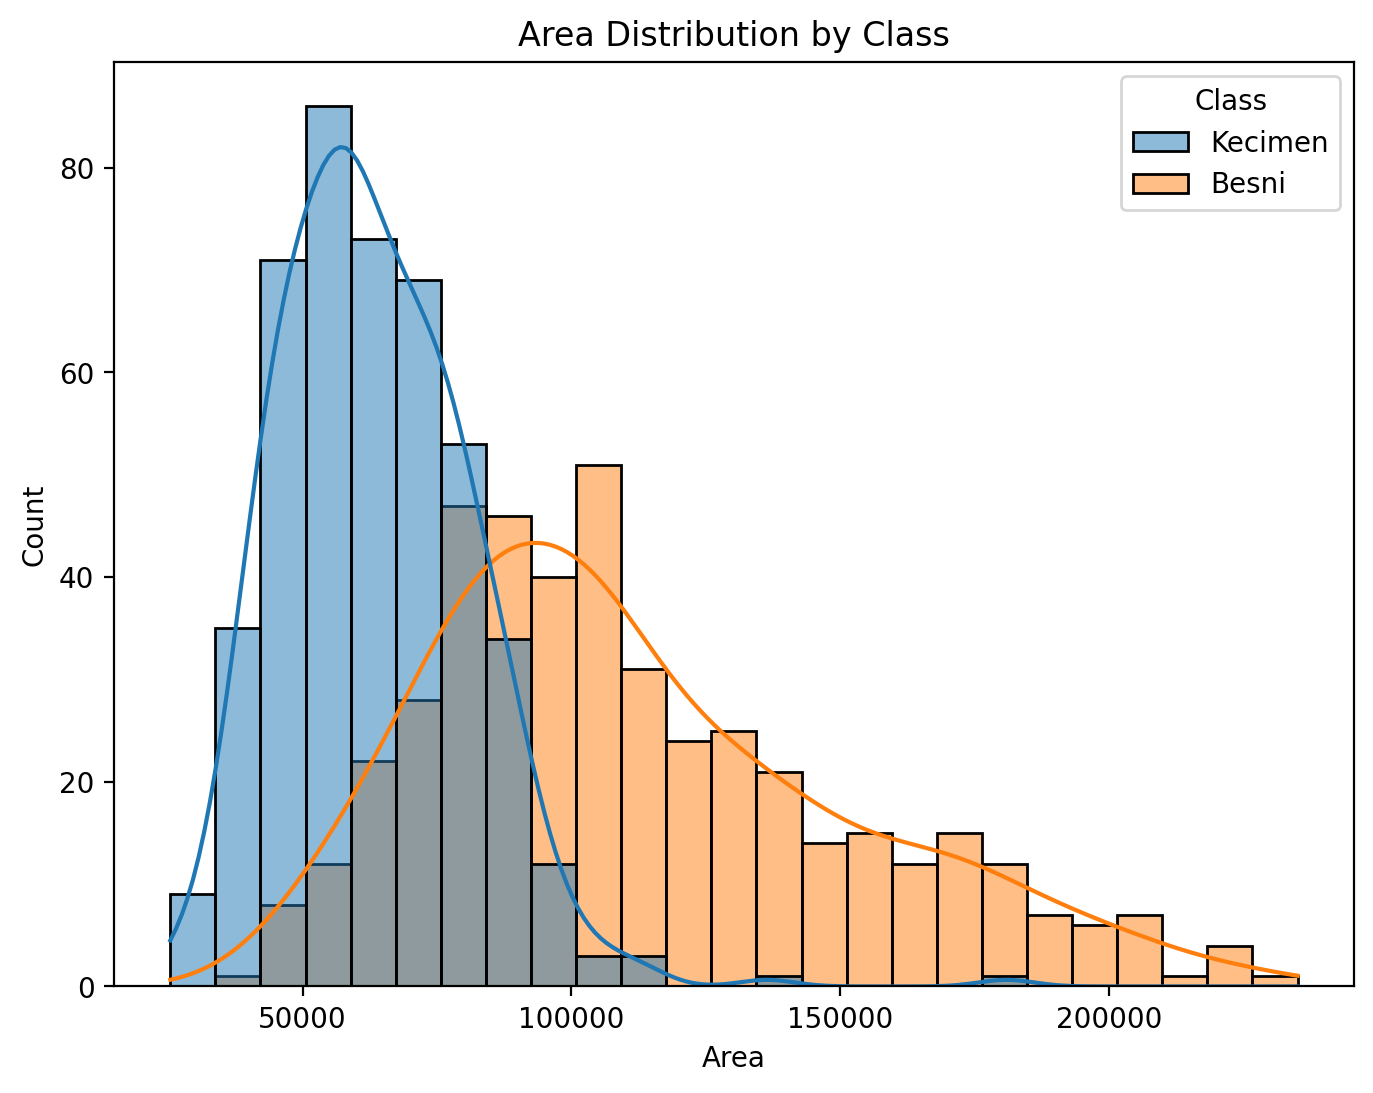

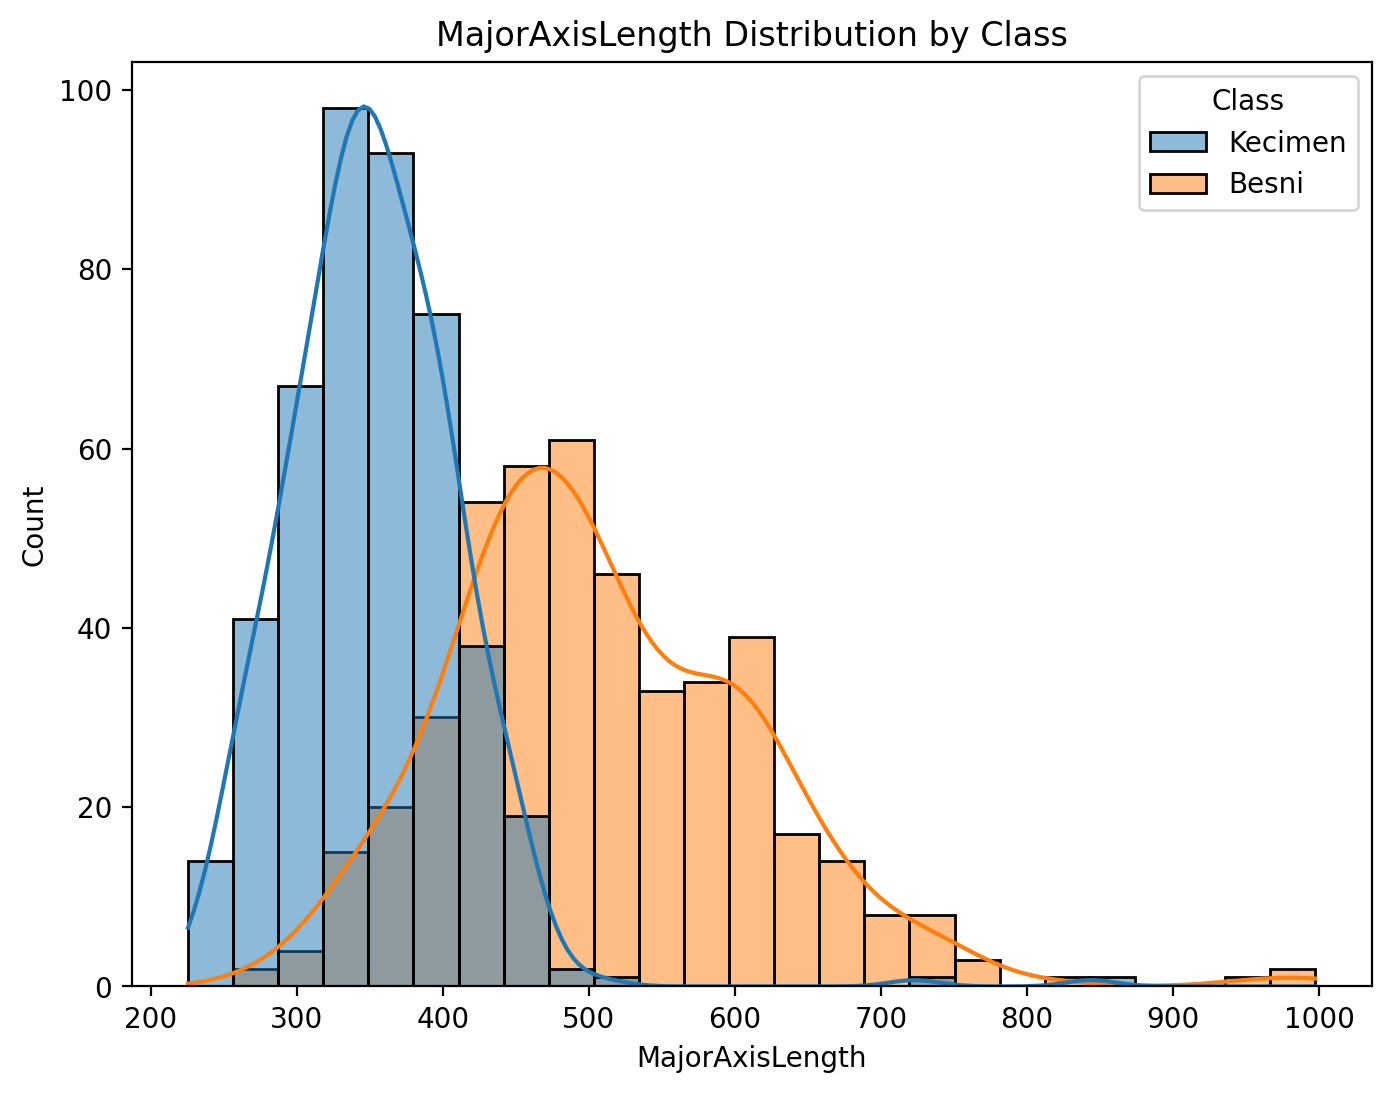

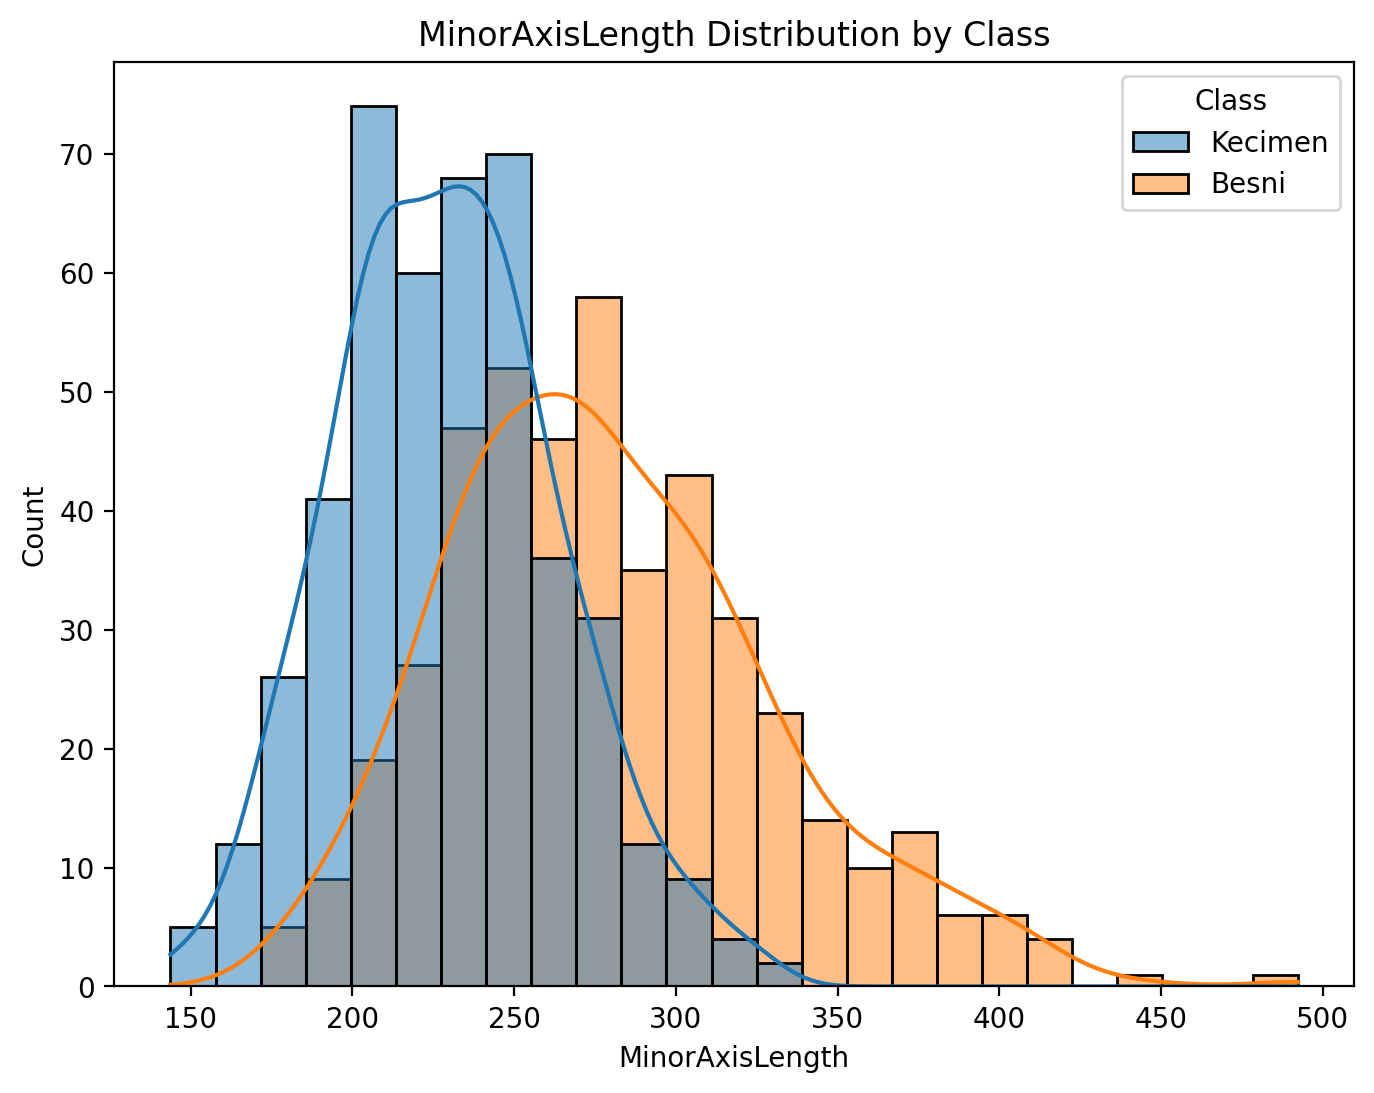

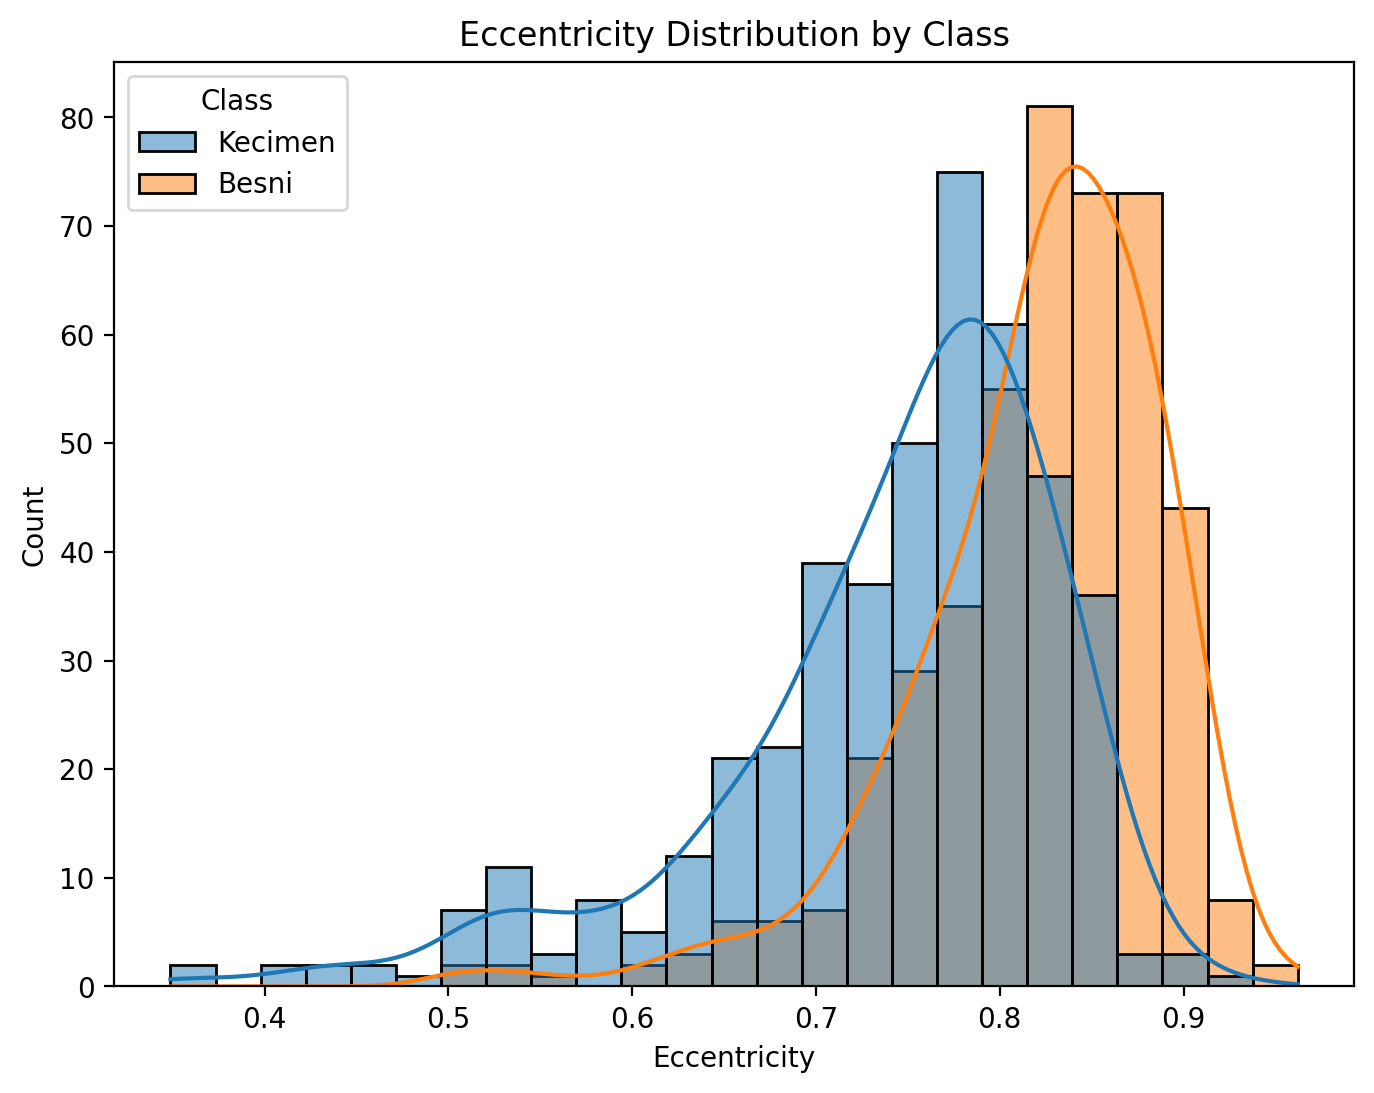

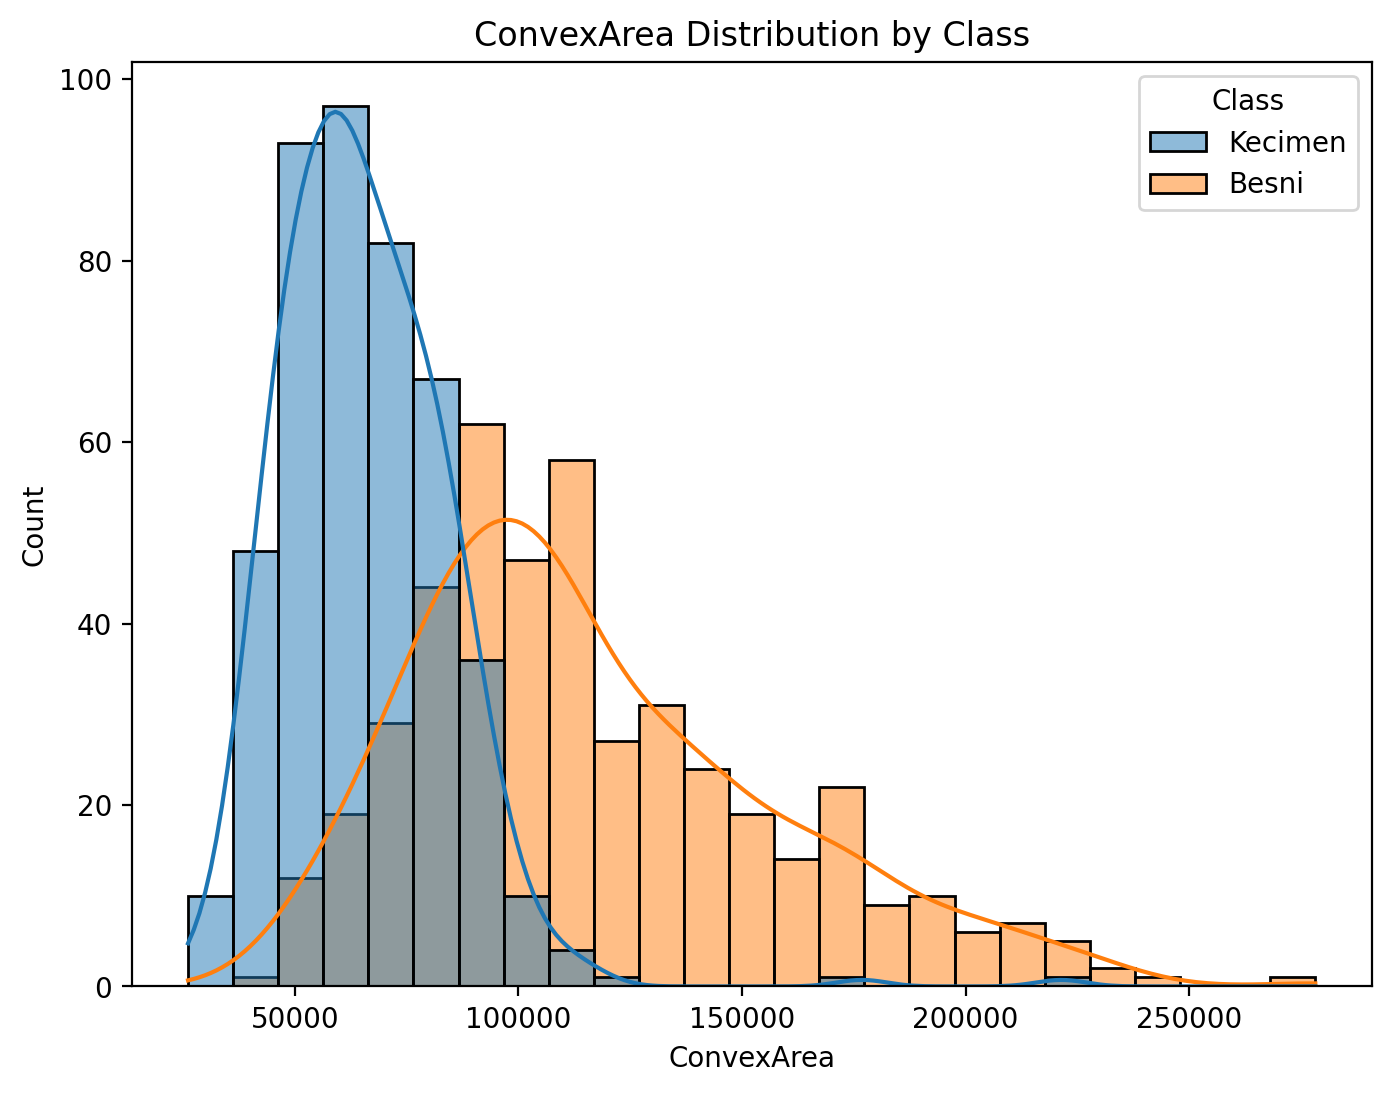

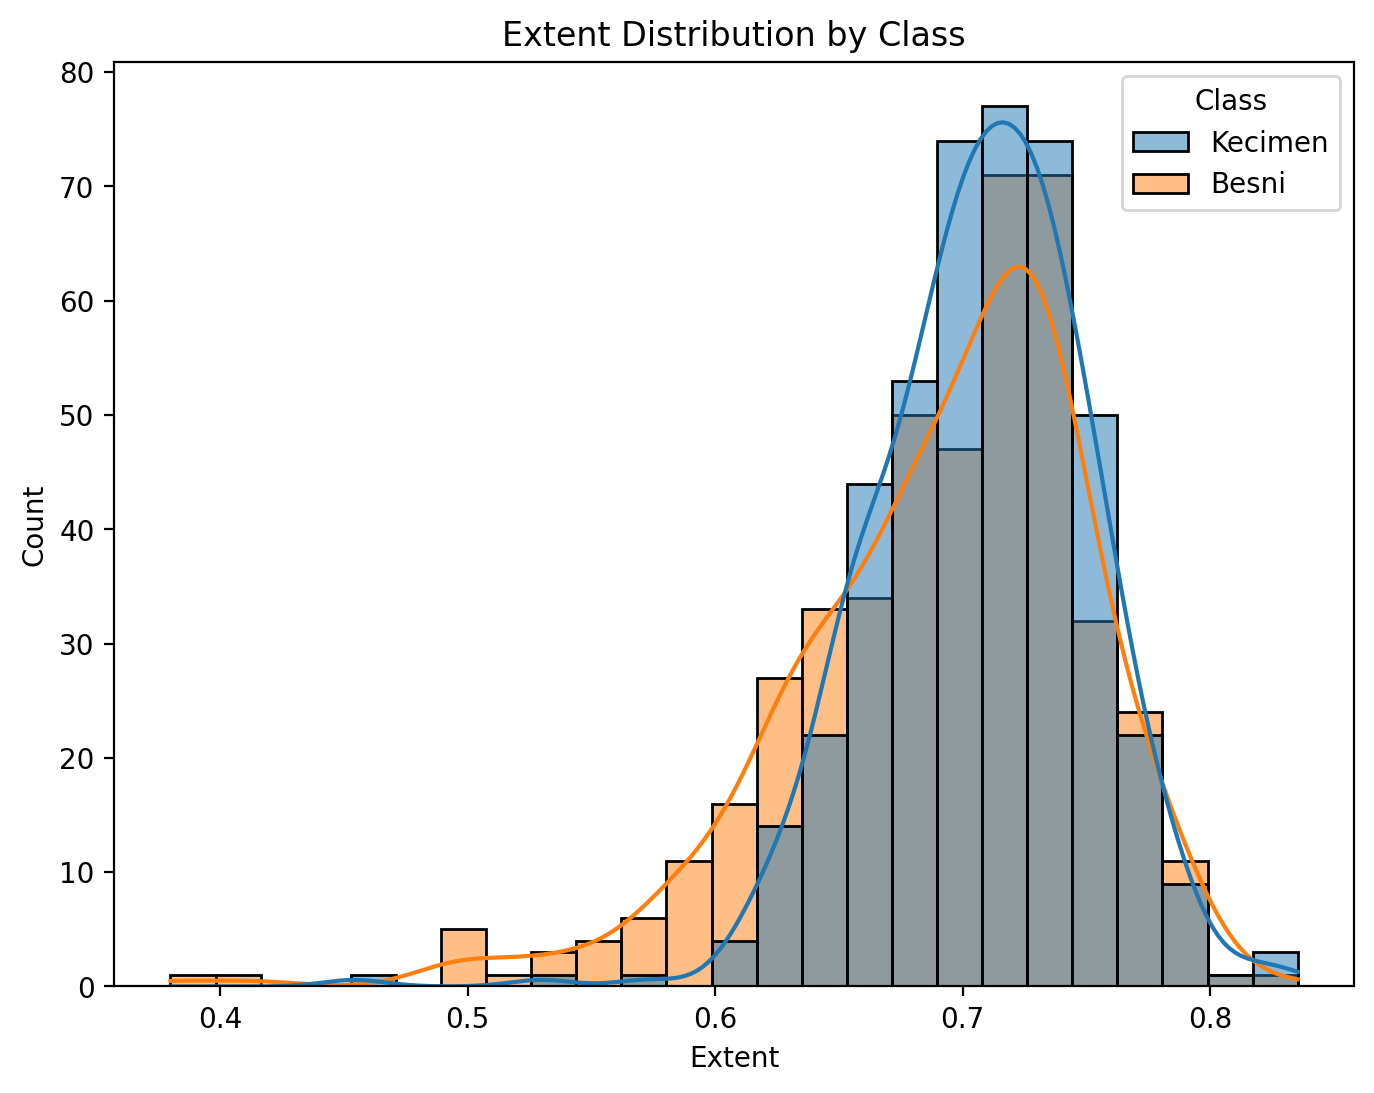

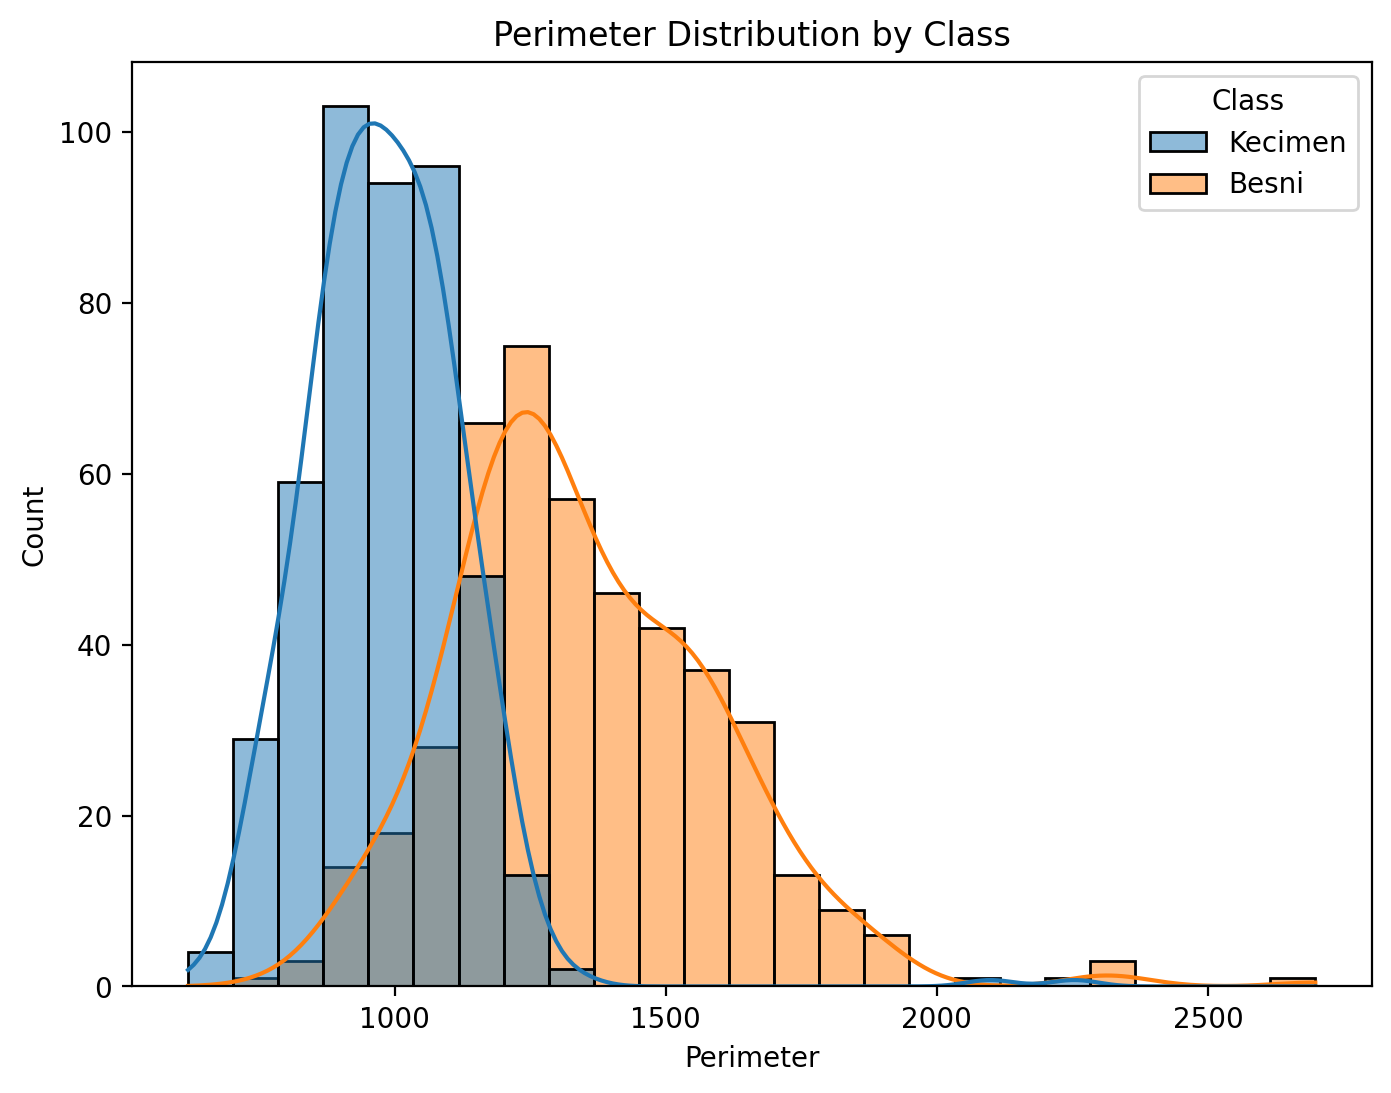

In [18]:
for column in numerical_features:
    plt.figure(figsize=(8,6))
    sns.histplot(data=df,x=column,hue="Class",kde=True,bins=25)
    plt.title(f"{column} Distribution by Class")
    plt.show()

### Correlation Matrix

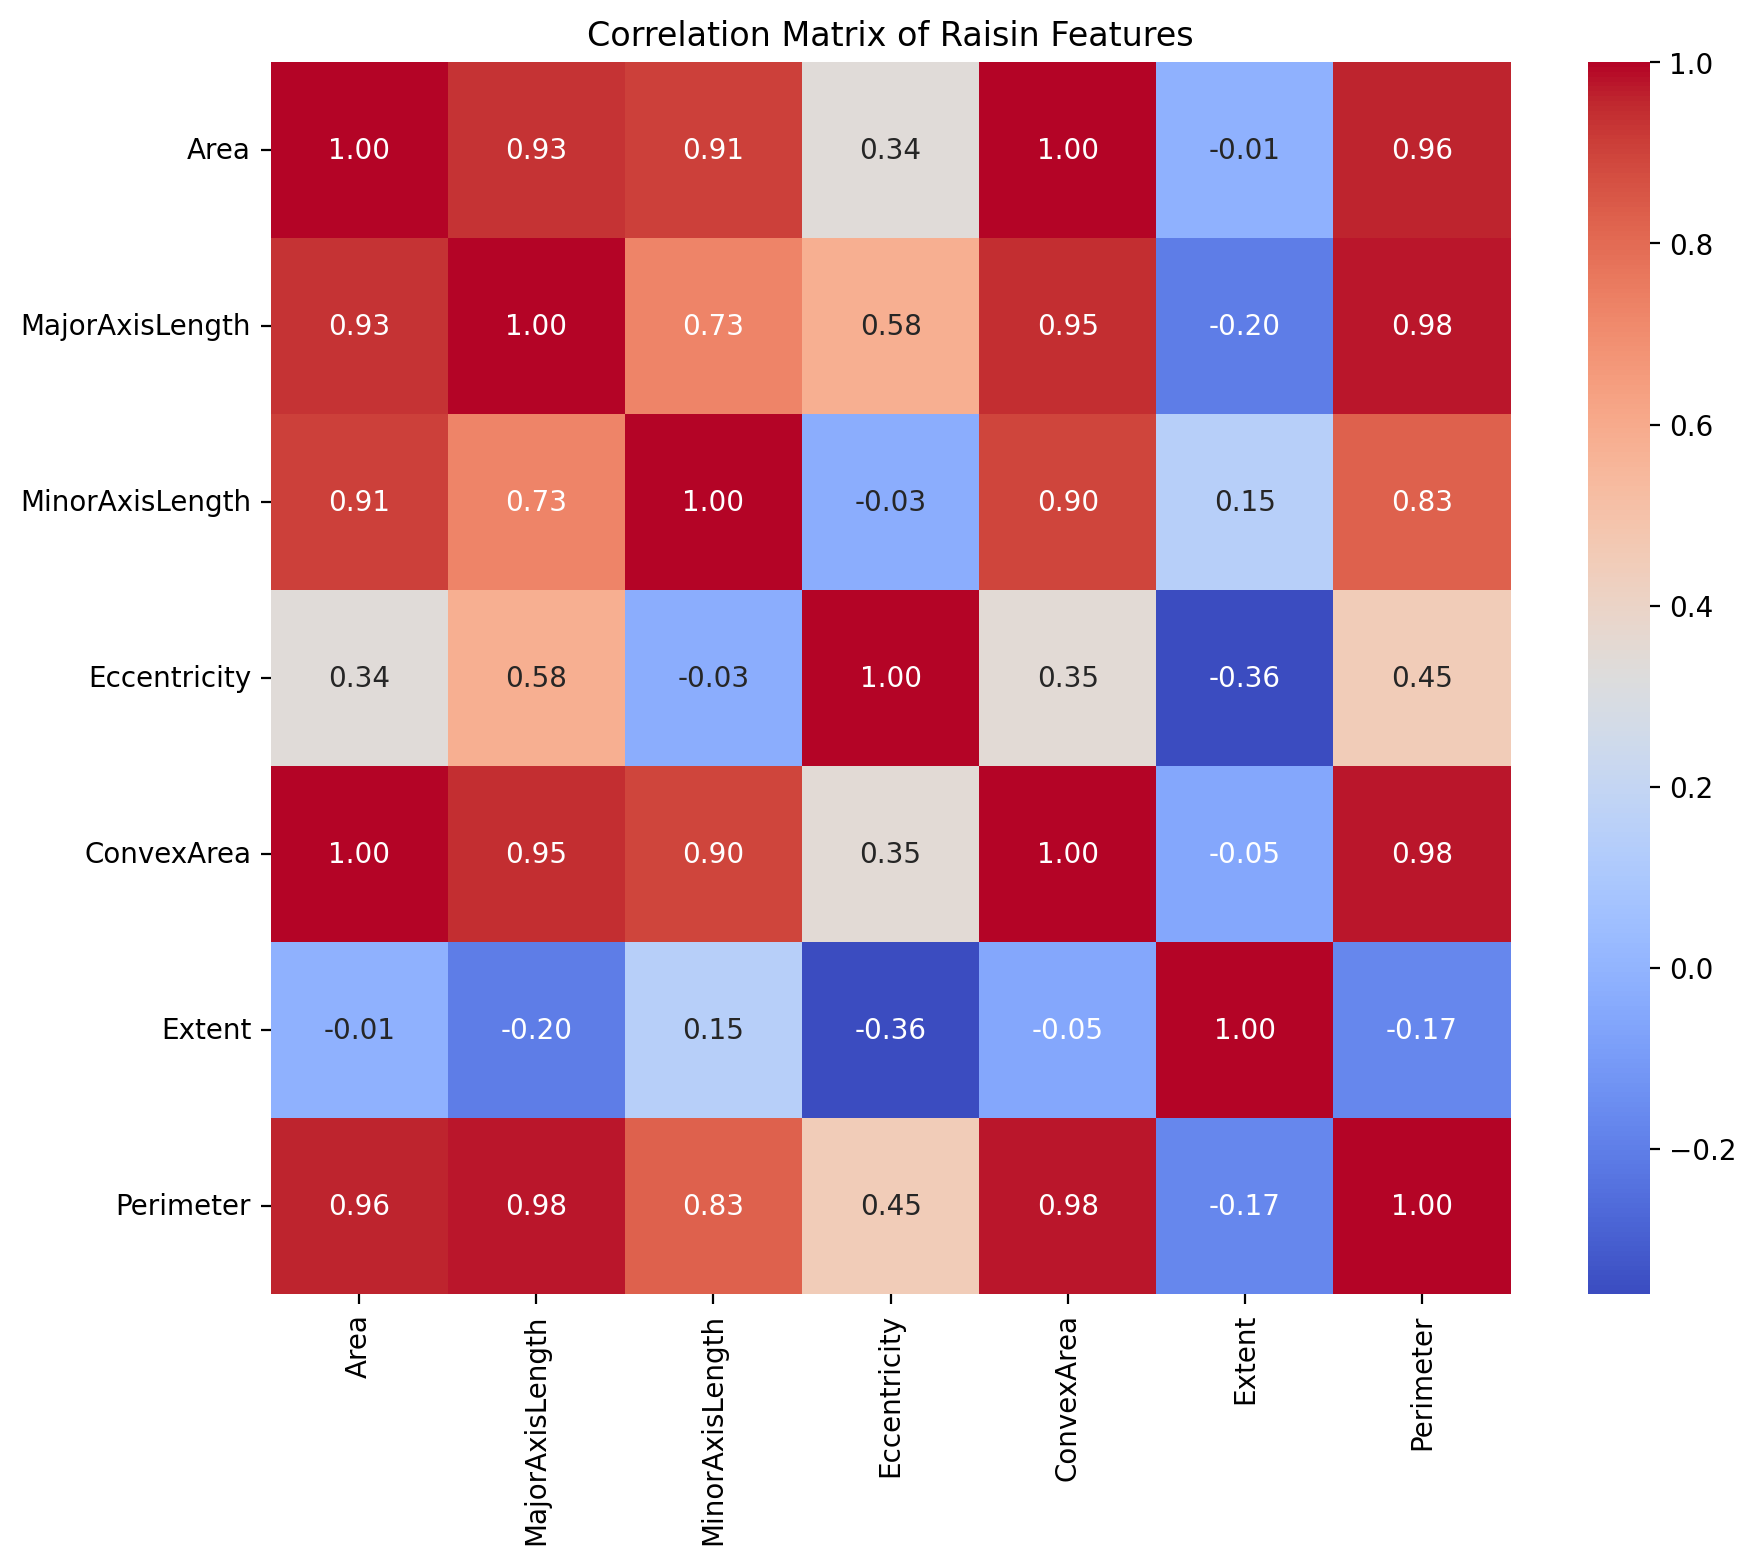

In [19]:
correlation_matrix=df[numerical_features].corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap='coolwarm')
plt.title("Correlation Matrix of Raisin Features")
plt.show()

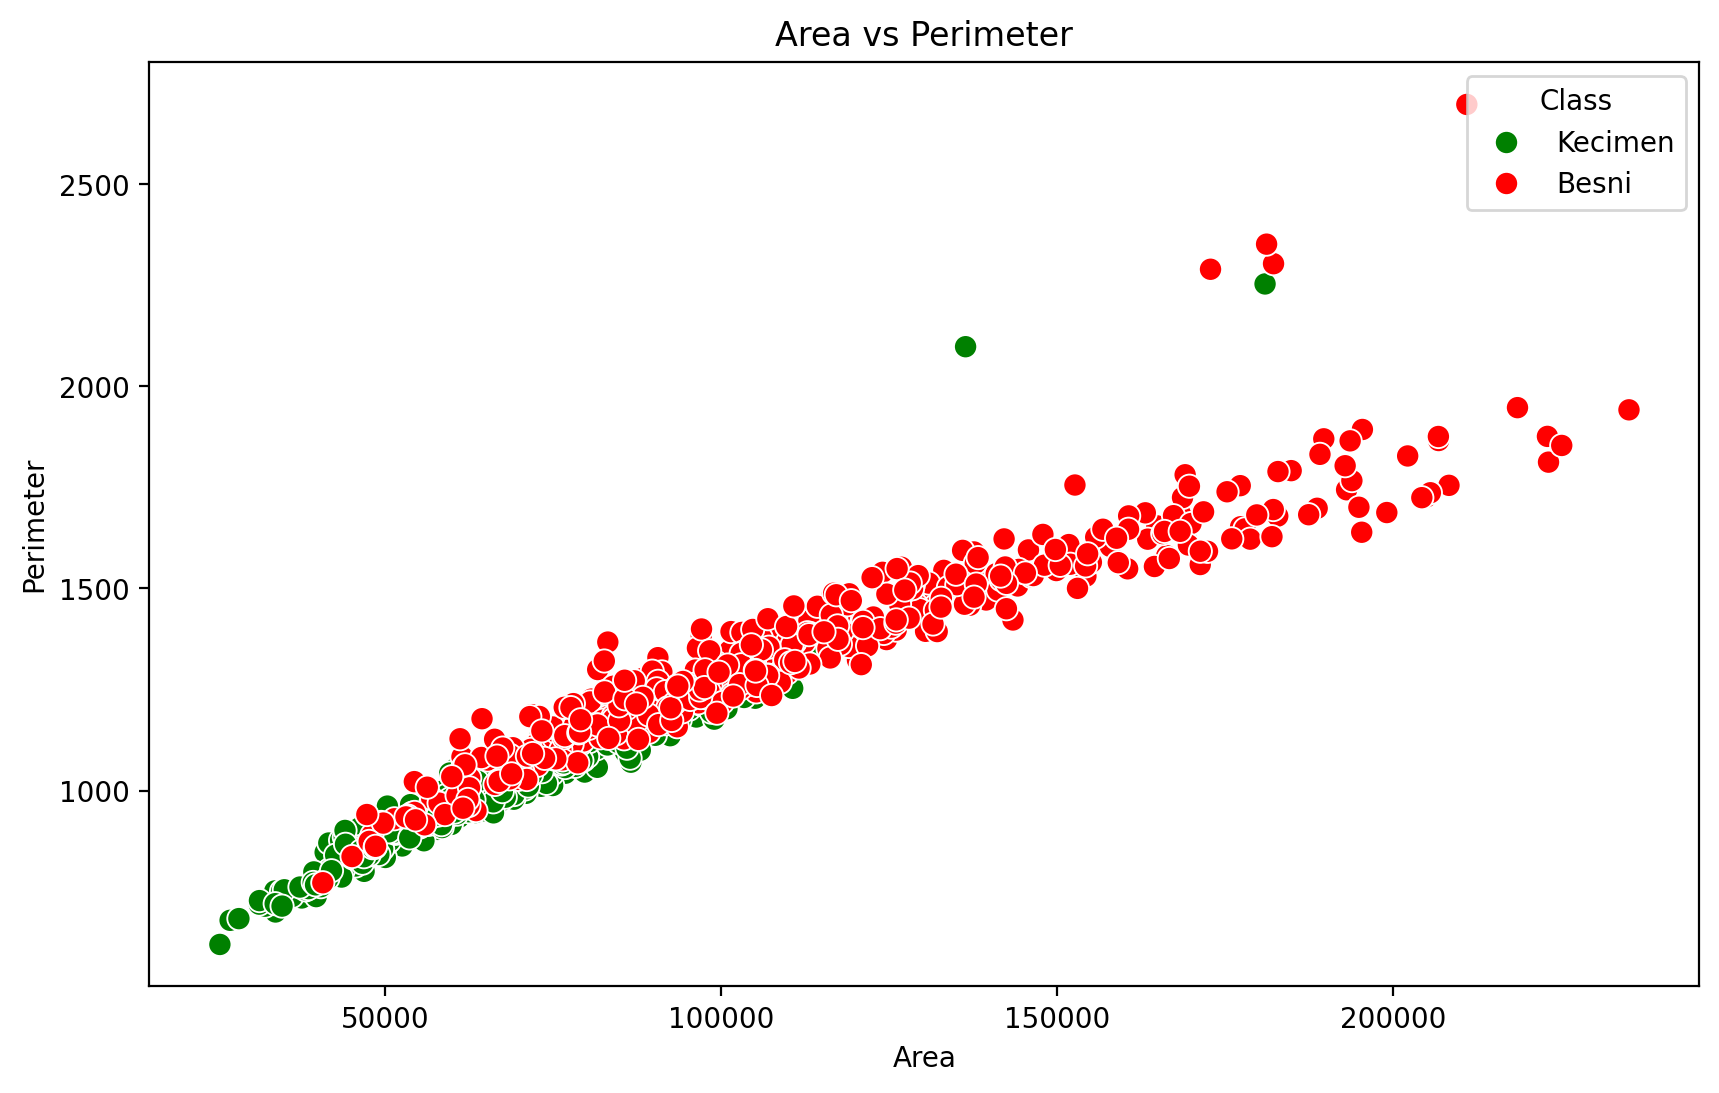

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Area",y="Perimeter",palette={'Kecimen':'Green','Besni':'Red'},
                hue="Class",
                s=70
)
plt.title("Area vs Perimeter")
plt.show()

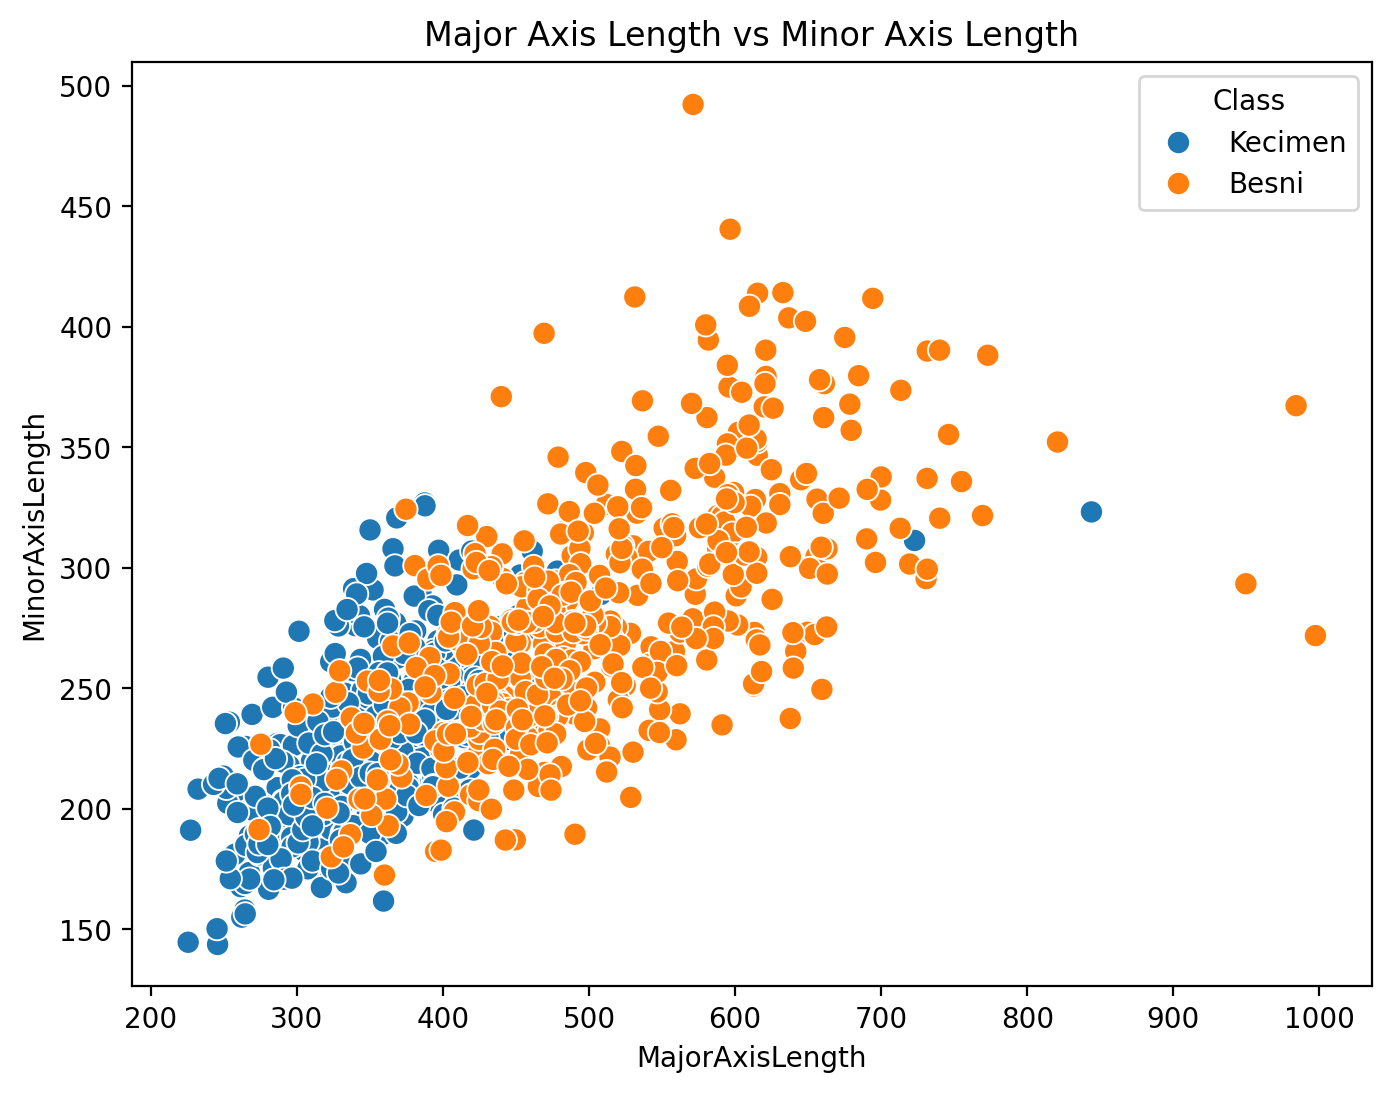

In [21]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x="MajorAxisLength",y="MinorAxisLength",
                hue="Class",
                s=70
)
plt.title("Major Axis Length vs Minor Axis Length")
plt.show()

### Data Preprocessing

In [22]:
#Data preprocessing
label_encoder=LabelEncoder()
df["Class_encoded"]=label_encoder.fit_transform(df["Class"])
print(df[["Class", "Class_encoded"]].head(10))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
5  Kecimen              1
6  Kecimen              1
7  Kecimen              1
8  Kecimen              1
9  Kecimen              1


In [23]:
print("Class mapping:")
for index, class_name in enumerate(label_encoder.classes_):
    print(index, "=",class_name)

Class mapping:
0 = Besni
1 = Kecimen


In [24]:
X=df[numerical_features]
y=df["Class_encoded"]
print("X shape:",X.shape)
print("y shape",y.shape)

X shape: (900, 7)
y shape (900,)


In [25]:
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Sample:",X_train.shape[0])
print("Testing Sample:",X_test.shape[0])

Training Sample: 720
Testing Sample: 180


### GaussianNB

In [26]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [27]:
y_pred = gnb.predict(X_test)
print("Predicted labels :")
print(y_pred)

Predicted labels :
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [28]:
comparison = pd.DataFrame({"Actual":y_test.values,"Predicted":y_pred})
print(comparison.head(5))

   Actual  Predicted
0       0          1
1       0          0
2       0          0
3       1          1
4       0          0


In [29]:
comparison["Actual_Class"] = label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted_Class"] = label_encoder.inverse_transform(comparison["Predicted"])
print(comparison.head(5))

   Actual  Predicted Actual_Class Predicted_Class
0       0          1        Besni         Kecimen
1       0          0        Besni           Besni
2       0          0        Besni           Besni
3       1          1      Kecimen         Kecimen
4       0          0        Besni           Besni


In [30]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("Accuracy(%):",accuracy*100)

Accuracy: 0.8166666666666667
Accuracy(%): 81.66666666666667


In [31]:
precision=precision_score(y_test,y_pred)
print("Precision:",precision)

Precision: 0.7522123893805309


In [32]:
recall=recall_score(y_test,y_pred)
print("Recall:",recall)

Recall: 0.9444444444444444


In [33]:
f1=f1_score(y_test,y_pred)
print("F1 Score:",f1)

F1 Score: 0.8374384236453202


In [34]:
print("====MODEL PERFORMANCE====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

====MODEL PERFORMANCE====
Accuracy : 0.8167
Precision : 0.7522
Recall : 0.9444
F1 Score : 0.8374


In [35]:
print(classification_report(y_test,y_pred,target_names=label_encoder.classes_))

              precision    recall  f1-score   support

       Besni       0.93      0.69      0.79        90
     Kecimen       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180



In [36]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[62 28]
 [ 5 85]]


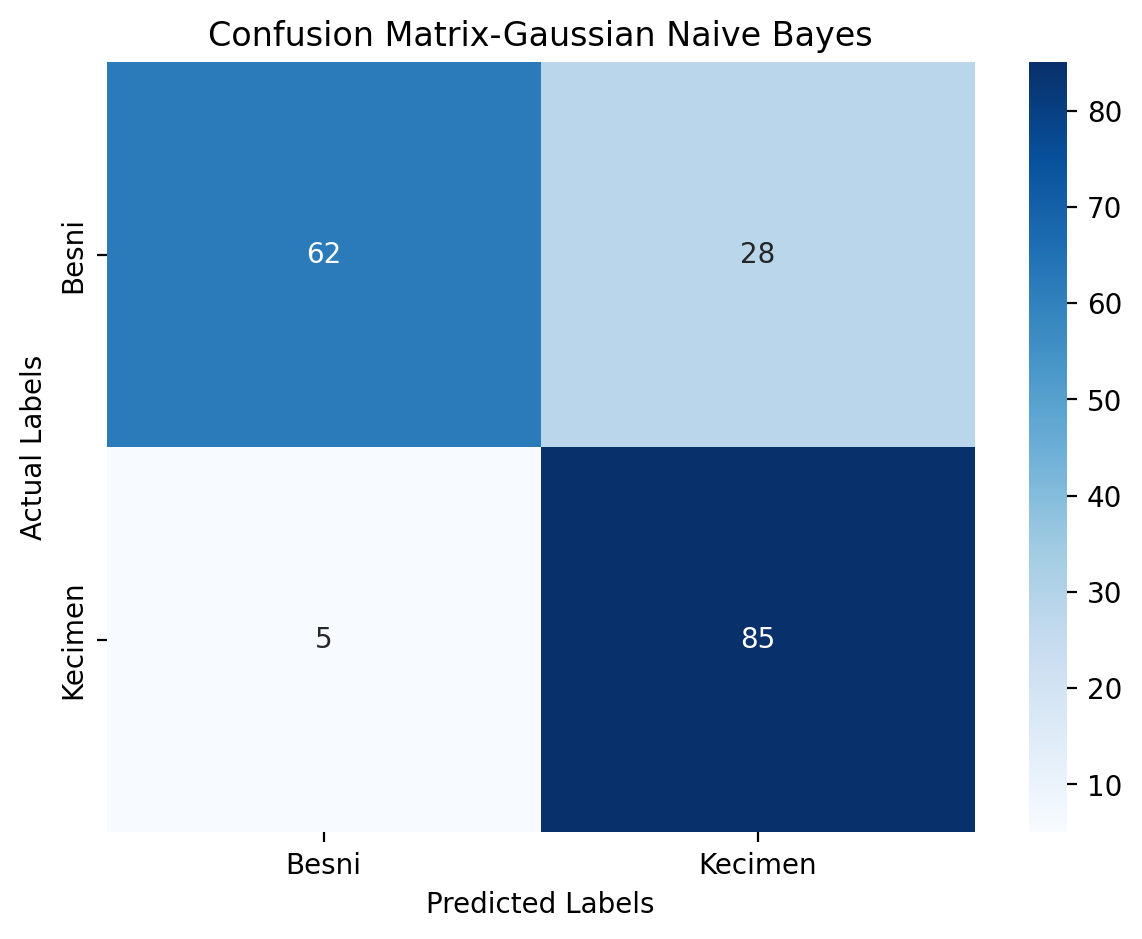

In [37]:
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix-Gaussian Naive Bayes")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.show()

In [38]:
y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy= accuracy_score(y_test, y_test_pred)
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8263888888888888
Testing Accuracy: 0.8166666666666667


### Main_Hyperparameters

In [39]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [40]:
smoothing_values = [1e-12, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3,1e-2]
results=[]

for value in smoothing_values:
  model =GaussianNB(var_smoothing=value)
  model.fit(X_train,y_train)
  prediction=model.predict(X_test)
  accuracy=accuracy_score(y_test,prediction)
  precision=precision_score(y_test,prediction)
  recall=recall_score(y_test,prediction)
  f1_value=f1_score(y_test,prediction)
  results.append([value,accuracy,precision,recall,f1_value])

In [41]:
results_df=pd.DataFrame(results,columns=["Smoothing Value","Accuracy","Precision","Recall","F1 Score"])
print(results_df)

   Smoothing Value  Accuracy  Precision    Recall  F1 Score
0     1.000000e-12  0.833333   0.767857  0.955556  0.851485
1     1.000000e-10  0.816667   0.752212  0.944444  0.837438
2     1.000000e-09  0.816667   0.752212  0.944444  0.837438
3     1.000000e-08  0.816667   0.752212  0.944444  0.837438
4     1.000000e-07  0.811111   0.745614  0.944444  0.833333
5     1.000000e-06  0.811111   0.745614  0.944444  0.833333
6     1.000000e-05  0.811111   0.741379  0.955556  0.834951
7     1.000000e-04  0.788889   0.720339  0.944444  0.817308
8     1.000000e-03  0.788889   0.720339  0.944444  0.817308
9     1.000000e-02  0.783333   0.714286  0.944444  0.813397


### Final Result

In [42]:
area = float(input("Enter Area:"))
major_axis_length = float(input("Enter Major Axis Length:"))
minor_axis_length = float(input("Enter Minor Axis Length:"))
eccentricity = float(input("Enter Eccentricity:"))
convex_area=float(input("Enter Convex Area:"))
extent=float(input("Enter Extent:"))
perimeter=float(input("Enter Perimeter:"))

new_sample=pd.DataFrame({
    "Area":[area],
    "MajorAxisLength":[major_axis_length],
    "MinorAxisLength":[minor_axis_length],
    "Eccentricity":[eccentricity],
    "ConvexArea":[convex_area],
    "Extent":[extent],
    "Perimeter":[perimeter]
})


prediction=gnb.predict(new_sample)

predicted_class=label_encoder.inverse_transform(prediction)
print("\nPredicted Raisin Class:",predicted_class[0])

Enter Area:93523
Enter Major Axis Length:476.34
Enter Minor Axis Length:254.18
Enter Eccentricity:0.8457
Enter Convex Area:97653
Enter Extent:0.6588
Enter Perimeter:1258.55

Predicted Raisin Class: Besni
